# Tabular — EDA Lengkap Sebelum Modeling (checklist 30 menit pertama)
**Isi:** profil kolom, sel kosong, duplikat, target, outlier, kategori langka, kategori yang
hanya ada di test, **kebocoran** (kolom yang terlalu mirip target), dan **drift** (train dan
test berbeda sebaran).

**Data demo:** Titanic. Sengaja ada kolom bocor (`alive` = salinan target) dan kolom kembar
(`class` = `pclass`). Ringkasan disimpan ke `eda_ringkasan.csv` (bahan laporan/presentasi).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/tabular/classification"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/titanic_train.csv"
TEST_CSV = f"{DATA_FOLDER}/titanic_test.csv"

TARGET = "survived"
ID_COL = "id"
NUM_COLS = ["pclass", "age", "sibsp", "parch", "fare"]
CAT_COLS = ["sex", "embarked", "class", "who", "adult_male", "deck", "embark_town", "alive",
            "alone"]
RARE_COUNT = 10           # kategori yang muncul < 10 kali dianggap langka
PSI_BINS = 10
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
FEATURES = NUM_COLS + CAT_COLS
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (712, 16) | test: (179, 15)


,id,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,693,1,3,male,NaN,0,0,56.4958,S,Third,man,True,NaN,Southampton,yes,True
1,482,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True
2,528,0,1,male,NaN,0,0,221.7792,S,First,man,True,C,Southampton,no,True
3,856,1,3,female,18.0,0,1,9.3500,S,Third,woman,False,NaN,Southampton,yes,False
4,802,1,2,female,31.0,1,1,26.2500,S,Second,woman,False,NaN,Southampton,yes,False


## 1. Profil kolom
Tipe, persen sel kosong di train dan test, jumlah nilai unik, satu contoh isi.

In [4]:
profile = pd.DataFrame()
profile["tipe"] = train.dtypes.astype(str)
profile["missing_train_%"] = (train.isna().mean() * 100).round(1)
profile["missing_test_%"] = (test.isna().mean() * 100).round(1)
profile["n_unik"] = train.nunique()
profile["contoh"] = train.iloc[0]
profile

,tipe,missing_train_%,missing_test_%,n_unik,contoh
id,int64,0.0,0.0,712,693
survived,int64,0.0,NaN,2,1
pclass,int64,0.0,0.0,3,3
sex,object,0.0,0.0,2,male
age,float64,19.2,22.3,85,NaN
sibsp,int64,0.0,0.0,7,0
parch,int64,0.0,0.0,7,0
fare,float64,0.0,0.0,226,56.4958
embarked,object,0.3,0.0,3,S
class,object,0.0,0.0,3,Third


## 2. Duplikat dan target
"Kembar tapi target beda" = baris dengan feature sama persis tetapi labelnya berbeda
(tanda label berisik, atau feature kurang lengkap).

In [5]:
print("baris kembar (semua feature sama):", train.duplicated(subset=FEATURES).sum())

duplicated_rows = train[train.duplicated(subset=FEATURES, keep=False)]
targets_per_group = duplicated_rows.groupby(FEATURES, dropna=False)[TARGET].nunique()
print("kembar tapi target beda:", (targets_per_group > 1).sum())
print("ID kembar:", train[ID_COL].duplicated().sum())
print(train[TARGET].value_counts(normalize=True).round(3))

baris kembar (semua feature sama): 71
kembar tapi target beda: 0
ID kembar: 0
survived
0    0.617
1    0.383
Name: proportion, dtype: float64


## 3. Kolom angka: sebaran dan outlier (aturan IQR)
Outlier atas = nilai > Q3 + 1.5 × (Q3 − Q1).

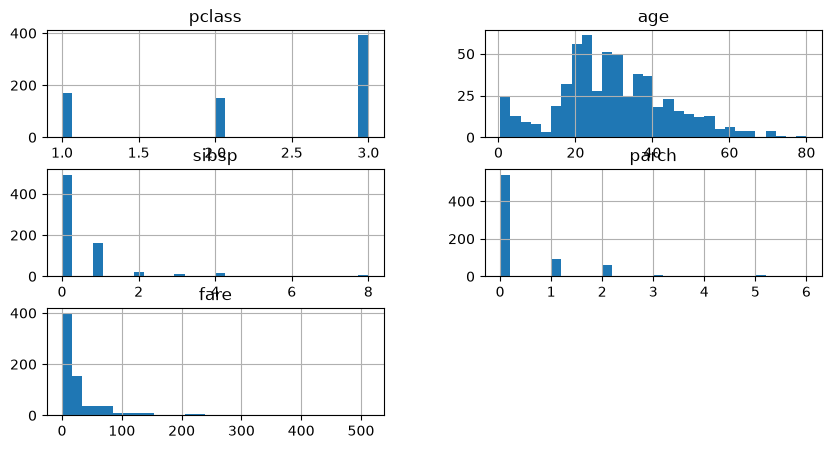

jumlah outlier atas per kolom:
pclass      0
age         6
sibsp      33
parch     170
fare       91
dtype: int64


In [6]:
train[NUM_COLS].hist(figsize=(10, 5), bins=30)
plt.show()

q1 = train[NUM_COLS].quantile(0.25)
q3 = train[NUM_COLS].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)
print("jumlah outlier atas per kolom:")
print((train[NUM_COLS] > upper_limit).sum())

## 4. Kategori: langka dan yang hanya muncul di test
Kategori yang hanya ada di test tidak pernah dilihat model → perlu `handle_unknown="ignore"`.

In [7]:
for col in CAT_COLS:
    counts = train[col].value_counts()
    only_in_test = set(test[col].dropna()) - set(train[col].dropna())
    rare = (counts < RARE_COUNT).sum()
    print(col, "| unik", len(counts), "| langka", rare, "| hanya di test:", only_in_test)

sex | unik 2 | langka 0 | hanya di test: set()
embarked | unik 3 | langka 0 | hanya di test: set()
class | unik 3 | langka 0 | hanya di test: set()
who | unik 3 | langka 0 | hanya di test: set()
adult_male | unik 2 | langka 0 | hanya di test: set()
deck | unik 7 | langka 1 | hanya di test: set()
embark_town | unik 3 | langka 0 | hanya di test: set()
alive | unik 2 | langka 0 | hanya di test: set()
alone | unik 2 | langka 0 | hanya di test: set()


## 5. Kebocoran: skor satu kolom saja terhadap target
Kolom kategori diubah ke kode angka dulu. AUC ≈ 1.0 dari satu kolom saja = curiga bocor
(isi kolom baru diketahui setelah target terjadi).

In [8]:
codes = pd.DataFrame()
for col in FEATURES:
    if col in CAT_COLS:
        codes[col] = train[col].astype("category").cat.codes
    else:
        codes[col] = train[col].fillna(-1)

leak_auc = pd.Series(dtype=float)
for col in FEATURES:
    auc = roc_auc_score(train[TARGET], codes[col])
    leak_auc[col] = max(auc, 1 - auc)
leak_auc = leak_auc.sort_values()
print(leak_auc.tail(6).round(3))
print("korelasi ID dengan target:", round(train[ID_COL].corr(train[TARGET]), 3))

class         0.685
who           0.691
fare          0.703
sex           0.770
adult_male    0.783
alive         1.000
dtype: float64
korelasi ID dengan target: 0.012


## 6. Kolom kembar / sangat berkorelasi (salah satunya bisa dibuang)
Korelasi Spearman antar semua pasangan kolom; tampilkan yang > 0.9.

In [9]:
correlation = codes.corr(method="spearman").abs()
for i in range(len(FEATURES)):
    for other in range(i + 1, len(FEATURES)):
        value = correlation.iloc[i, other]
        if value > 0.9:
            print(FEATURES[i], "~", FEATURES[other], ":", round(value, 3))

pclass ~ class : 1.0
sex ~ adult_male : 0.911
embarked ~ embark_town : 1.0


## 7. Drift train vs test: uji KS (kolom angka) dan PSI
- KS p-value kecil (< 0.05) = sebaran train dan test berbeda.
- PSI < 0.1 aman, 0.1–0.25 waspada, > 0.25 bergeser jauh.
  PSI membandingkan persen data di tiap kelompok (bin) train vs test.

In [10]:
def psi(train_values, test_values):
    edges = np.unique(np.nanquantile(train_values, np.linspace(0, 1, PSI_BINS + 1)))
    test_values = np.clip(test_values, edges[0], edges[-1])
    train_share = np.histogram(train_values, edges)[0] / len(train_values) + 1e-4
    test_share = np.histogram(test_values, edges)[0] / len(test_values) + 1e-4
    return float(np.sum((train_share - test_share) * np.log(train_share / test_share)))


drift = pd.DataFrame(index=NUM_COLS)
for col in NUM_COLS:
    train_values = train[col].dropna()
    test_values = test[col].dropna()
    drift.loc[col, "ks_pvalue"] = stats.ks_2samp(train_values, test_values).pvalue
    drift.loc[col, "psi"] = psi(train_values, test_values)
drift.round(4)

,ks_pvalue,psi
pclass,1.0000,0.0007
age,0.4835,0.1196
sibsp,0.7157,0.0146
parch,1.0000,0.0000
fare,0.8053,0.0581


## 8. Hubungan feature dengan target (mutual information)
Makin panjang batangnya, makin banyak informasi kolom itu tentang target.

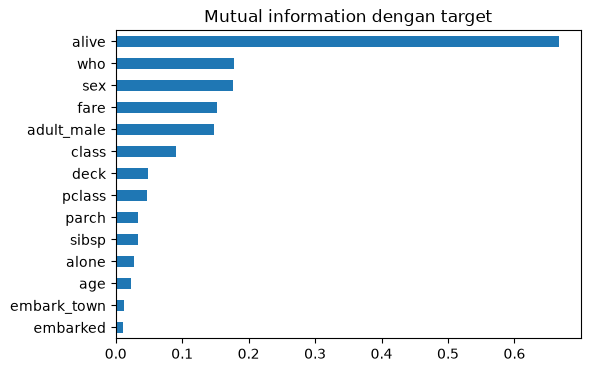

In [11]:
mutual_info = mutual_info_classif(codes.fillna(-1), train[TARGET], random_state=SEED)
mutual_info = pd.Series(mutual_info, index=FEATURES)
mutual_info.sort_values().plot.barh(figsize=(6, 4))
plt.title("Mutual information dengan target")
plt.show()

## Ringkasan → CSV

In [12]:
summary = profile.copy()
summary["auc_satu_kolom"] = leak_auc
summary["psi_train_test"] = drift["psi"]
summary.to_csv("eda_ringkasan.csv")
print("kolom curiga bocor:", list(leak_auc[leak_auc > 0.95].index))
summary

kolom curiga bocor: ['alive']


,tipe,missing_train_%,missing_test_%,n_unik,contoh,auc_satu_kolom,psi_train_test
id,int64,0.0,0.0,712,693,NaN,NaN
survived,int64,0.0,NaN,2,1,NaN,NaN
pclass,int64,0.0,0.0,3,3,0.684802,0.000680
sex,object,0.0,0.0,2,male,0.770290,NaN
age,float64,19.2,22.3,85,NaN,0.517360,0.119611
sibsp,int64,0.0,0.0,7,0,0.546868,0.014588
parch,int64,0.0,0.0,7,0,0.564979,0.000038
fare,float64,0.0,0.0,226,56.4958,0.703234,0.058140
embarked,object,0.3,0.0,3,S,0.590440,NaN
class,object,0.0,0.0,3,Third,0.684802,NaN
